In [1]:
import sys; sys.path.append("..")               # sys.path is a built-in list that comes with Python's sys module, It holds the folders Python searches when you write import!!
from src.ecommerce import EcommerceAnalyzer

analyzer = EcommerceAnalyzer()



## Sherifs Analys för fråga (3):

Rapporteringsperioden sträcker sig från '2024-01-01' till '2024-06-30'


Veckodag intäktsöversiktsstatistik:
                 sum     mean  count
weekday                             
Monday     527263.73  1432.78    368
Tuesday    512978.35  1449.09    354
Wednesday  502661.61  1452.78    346
Thursday   518871.71  1437.32    361
Friday     501396.53  1404.47    357
Saturday   481483.77  1356.29    355
Sunday     458111.53  1276.08    359



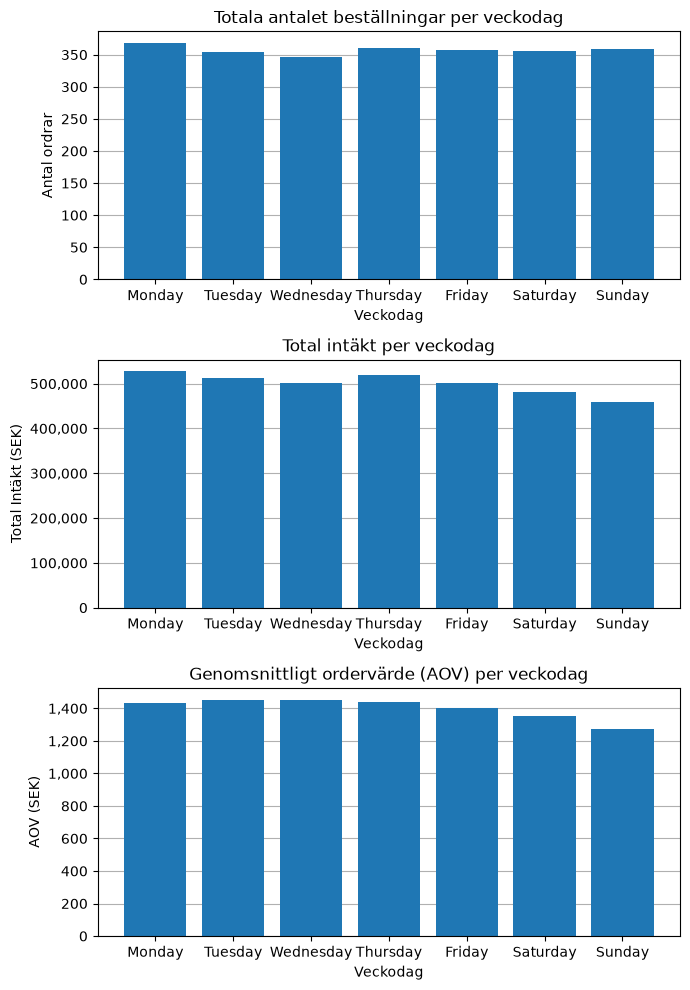

In [2]:
# --- När säljer vi? ---

# analyze perioden
start, end = analyzer.date_range()
print(f"Rapporteringsperioden sträcker sig från '{start:%Y-%m-%d}' till '{end:%Y-%m-%d}'\n")

print()

# Get  weekdays revenue summary
weekday_rev_summ = analyzer.weekday_revenue_summary()
print("Veckodag intäktsöversiktsstatistik:")
print(weekday_rev_summ)

print()

analyzer.plot_weekday_overview()

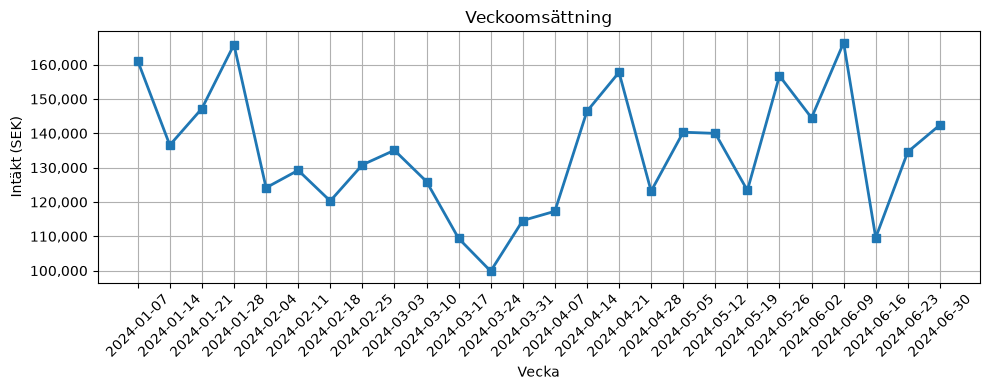

In [3]:
# Get  weekly revenue summary
weekly_rev_summ = analyzer.weekly_revenue_summary()
# print("Daglig intäktsöversiktsstatistik:")
# print(weekly_rev_summ)

analyzer.plot_weekly_revenue()


månatliga intäkter och procentuell förändring från månad till månad (MoM %):
               sum     mean  count  pct_change
period                                        
2024-01  664083.32  1492.32    445         NaN
2024-02  548462.03  1536.31    357       -17.4
2024-03  487602.00  1186.38    411       -11.1
2024-04  580194.83  1343.04    432        19.0
2024-05  632165.16  1459.97    433         9.0
2024-06  590259.89  1398.72    422        -6.6



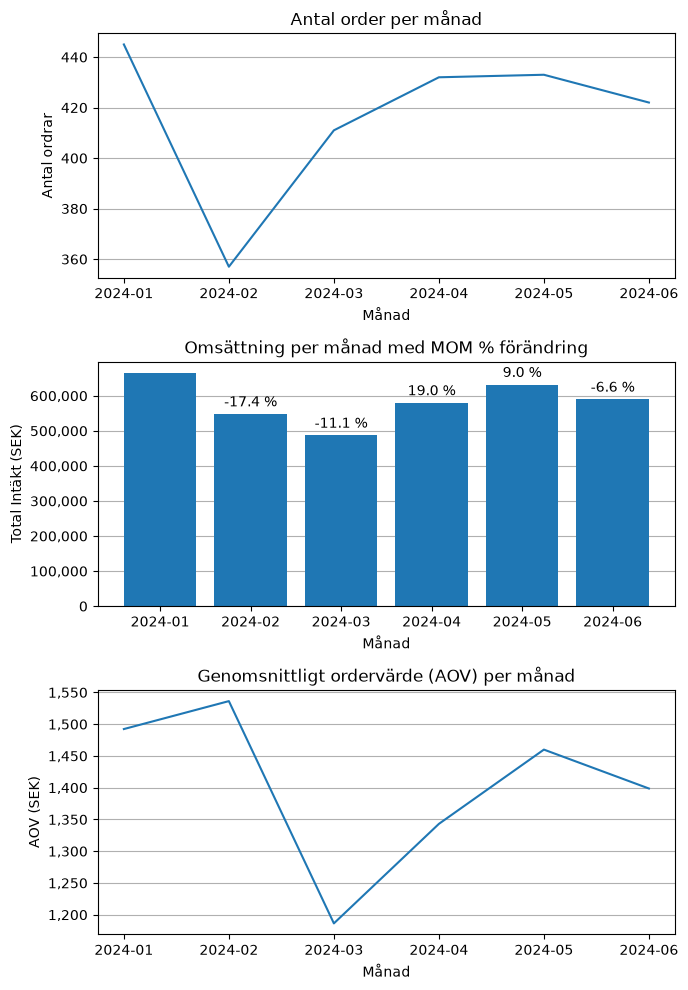

In [4]:
# Get monthly orders, revenue & revenue change
monthly_rev_change = analyzer.monthly_revenue_change()
print("månatliga intäkter och procentuell förändring från månad till månad (MoM %):")
print(monthly_rev_change)

print()

analyzer.plot_monthly_overview()

Intäkt, enheter och antal ordrar per kategori per månad (by_month=True):
                     total_revenue  units_sold  order_count
period  category                                           
2024-01 Electronics      320974.28         424          117
        Sports           117601.32         215           75
        Clothing         105282.27         296           97
        Home              65401.53         178           76
        Beauty            36266.24         138           47
        Toys              18557.68         102           33
2024-02 Electronics      294814.45         394           99
        Clothing          75706.91         218           72
        Sports            68657.21         138           53
        Home              66959.10         164           67
        Toys              25094.96         115           37
        Beauty            17229.40          68           29
2024-03 Electronics      171967.59         224           95
        Sports           10

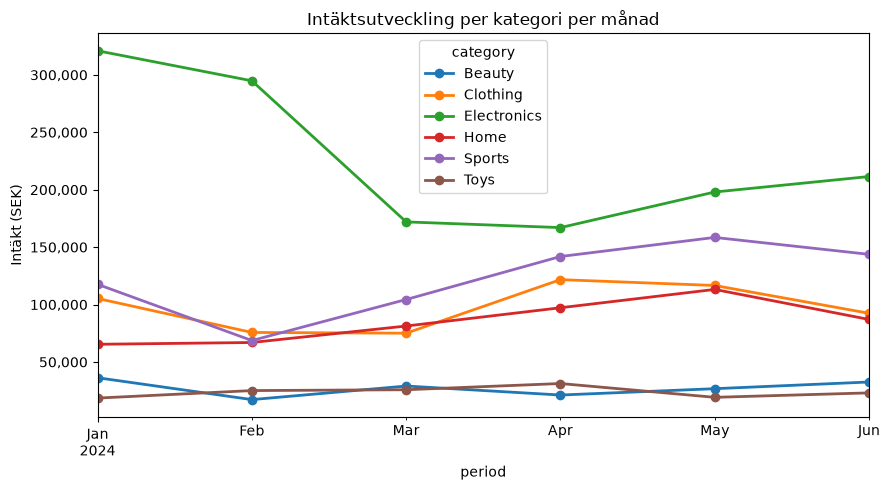

In [5]:
# --- Vad säljer vi? / Var säljer vi? ---

# category_performance(grupperar per månad och kategori):
category_perf_summ = analyzer.category_performance(by_month=True)
print("Intäkt, enheter och antal ordrar per kategori per månad (by_month=True):")
print(category_perf_summ)

print()

analyzer.plot_category_trends()


Intäkt, enheter och AOV per stad per månad (by_month=True):
                   total_revenue  units_sold          aov
period  city                                             
2024-01 Stockholm      231480.69         440  1522.899276
        Göteborg       162733.76         334  1535.224151
        Malmö          112625.48         235  1542.814795
        Uppsala        105786.37         226  1429.545541
        Västerås        51457.02         118  1286.425500
2024-02 Stockholm      183273.71         380  1514.658760
        Göteborg       143196.98         275  1627.238409
        Malmö           97203.92         200  1495.444923
        Uppsala         85550.63         152  1711.012600
        Västerås        39236.79          90  1188.993636
2024-03 Stockholm      186238.86         432  1121.920843
        Göteborg       106729.36         229  1368.325128
        Uppsala         76579.99         178  1178.153692
        Malmö           71195.67         170  1186.594500
        Väst

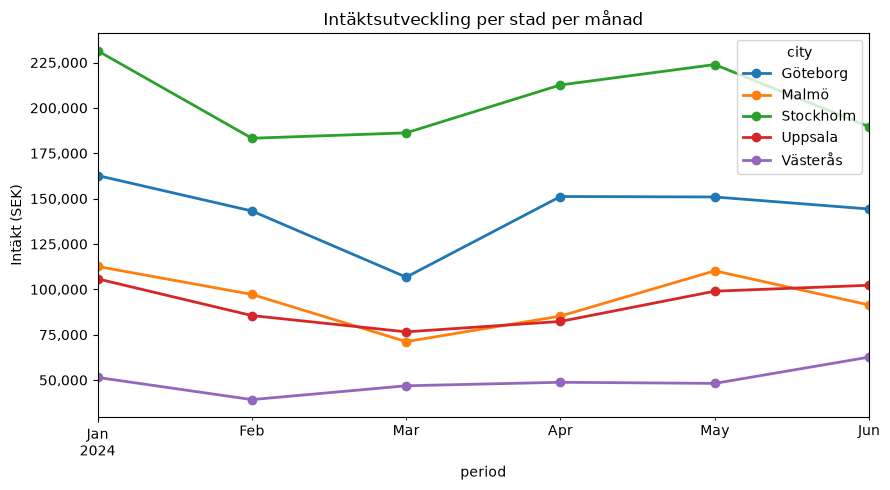

In [6]:
# city_performance(grupperar per månad och city):
city_perf_summ = analyzer.city_performance(by_month=True)
print("Intäkt, enheter och AOV per stad per månad (by_month=True):")
print(city_perf_summ)

print()

analyzer.plot_city_trends()


### Sammanfattning – När säljer vi?

Perioden omfattar 1 januari – 30 juni 2024 (2 500 ordrar).

1. **Månader:** Januari är starkast (664 083 SEK) och mars svagast (487 602 SEK) efter två nedgångar i rad (−17,4 % och −11,1 %). April ökade med 19 % men nådde inte upp till januari–februari.

2. **Orsak till marsdippen:** Antalet ordrar låg kvar på normal nivå (411), men AOV sjönk till 1 186 SEK mot 1 536 SEK i februari – kunderna handlade lika ofta men för mindre belopp.

3. **Veckor:** Svagast var v. 12 (18–24 mars, 99 853 SEK). Starkast var v. 4 (22–28 januari, 165 833 SEK) och v. 23 (3–9 juni, 166 384 SEK), i stort sett lika höga.

4. **Veckodagar:** Antalet ordrar är jämnt (354–368 per dag), men intäkten är lägst på lördag (−3,8 %) och söndag (−8,5 % mot snittet) eftersom AOV sjunker mot helgen (1 276 SEK på söndag) – samma mekanism som i mars.

5. **Kategori och stad över tid:** Elektronik är störst (främst januari–februari), följd av sport (maj–juni) och kläder (april–maj); skönhet och leksaker är minst. Stockholm och Göteborg leder, Västerås är lägst.



## Rekommendationer

1. **Höj ordervärdet i svaga perioder (mars och helger).** Dipparna beror på lägre AOV, inte färre ordrar. *Åtgärd:* paketerbjudanden, merförsäljning i kassan och en tröskel för fri frakt i mars och på söndagar.

2. **Planera kampanjer efter kategoriernas starka månader.** Elektronik toppar i januari–februari (321 000 SEK i januari), kläder i april–maj och sport i maj–juni. *Åtgärd:* fördela kampanjer och marknadsföring efter dessa toppar.

3. **Prioritera Stockholm och Göteborg.** De står för cirka 60 % av intäkterna; Västerås är lägst varje månad. *Åtgärd:* lägg den geografiskt riktade marknadsföringen där volymen finns.

*Begränsning:* Datan täcker bara sex månader, så vi kan inte avgöra om mönstren är säsongsbundna. Åtgärderna bör testas och följas


## slutet på Sherifs analysavsnitt för fråga (3).
    